# Descripción

La compañía de seguros Sure Tomorrow quiere resolver varias tareas con la ayuda de machine learning y te pide que evalúes esa posibilidad.

- Tarea 1: encontrar clientes que sean similares a un cliente determinado. Esto ayudará a los agentes de la compañía con el marketing.
- Tarea 2: predecir la probabilidad de que un nuevo cliente reciba una prestación del seguro. ¿Puede un modelo de predictivo funcionar mejor que un modelo dummy?
- Tarea 3: predecir el número de prestaciones de seguro que un nuevo cliente pueda recibir utilizando un modelo de regresión lineal.
- Tarea 4: proteger los datos personales de los clientes sin afectar al modelo del ejercicio anterior. Es necesario desarrollar un algoritmo de transformación de datos que dificulte la recuperación de la información personal si los datos caen en manos equivocadas. Esto se denomina enmascaramiento u ofuscación de datos. Pero los datos deben protegerse de tal manera que no se vea afectada la calidad de los modelos de machine learning. No es necesario elegir el mejor modelo, basta con demostrar que el algoritmo funciona correctamente.


# Preprocesamiento y exploración de datos

## Inicialización

In [42]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

import math
import sklearn.linear_model
import sklearn.metrics
from sklearn.neighbors import NearestNeighbors
from sklearn.neighbors import KNeighborsClassifier
import sklearn.preprocessing

from sklearn.model_selection import train_test_split

from IPython.display import display

## Carga de datos

In [43]:
df = pd.read_csv('/content/insurance_us.csv')
df_original = pd.read_csv('/content/insurance_us.csv')

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Gender              5000 non-null   int64  
 1   Age                 5000 non-null   float64
 2   Salary              5000 non-null   float64
 3   Family members      5000 non-null   int64  
 4   Insurance benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


Renombramos las columnas para que el código se vea más coherente con su estilo.

In [45]:
df = df.rename(columns={'Gender': 'gender', 'Age': 'age', 'Salary': 'income', 'Family members': 'family_members', 'Insurance benefits': 'insurance_benefits'})

In [46]:
df.sample(10)

,gender,age,income,family_members,insurance_benefits
1746,0,47.0,42700.0,0,1
4288,0,45.0,53600.0,1,1
3224,0,44.0,50200.0,1,1
3139,1,43.0,32200.0,2,1
788,1,30.0,63200.0,1,0
2130,1,37.0,31500.0,1,0
1984,0,39.0,44600.0,3,0
2711,0,33.0,46500.0,3,0
1007,1,19.0,57200.0,2,0
1295,0,37.0,30400.0,0,0


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   float64
 2   income              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


No consideramos que sea vital pero por cuestión de orden vamos a modificar el tipo de datos de edad, convirtiéndolo de decimal(float64) a entero(int64)

In [48]:
df["age"] = df["age"].astype("int64")

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   int64  
 2   income              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 195.4 KB


Revisaremos rápidamente si hay presencia de valores ausentes. No analizaremos en este caso los datos duplicados, ya que al contener datos numéricos no representa un error o una falla de lógica en el conjunto de información. Es aceptable que podamos tener duplicados en los números como edad o género.

In [50]:
df.isna().sum()

,0
gender,0
age,0
income,0
family_members,0
insurance_benefits,0


In [51]:
df.describe()

,gender,age,income,family_members,insurance_benefits
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.499000,30.952800,39916.360000,1.194200,0.148000
std,0.500049,8.440807,9900.083569,1.091387,0.463183
min,0.000000,18.000000,5300.000000,0.000000,0.000000
25%,0.000000,24.000000,33300.000000,0.000000,0.000000
50%,0.000000,30.000000,40200.000000,1.000000,0.000000
75%,1.000000,37.000000,46600.000000,2.000000,0.000000
max,1.000000,65.000000,79000.000000,6.000000,5.000000


Por ahora podemos decir mediante un breve análisis estadístico de los datos que los clientes que presentan la mayor edad registrada son de 65 años, naturalmente la edad mínima que registramos es de 18.

Podemos obervar que la edad media de los clientes ronda los 30/31 años

la cantidad media de miembros de familia de los clientes se registra en 1

Observando los ingresos, podemos decir que se tratan de ingresos anuales que según la media es alrededor de 40.900 dolares al año, el ingreso más pequeño resgistado es de 5.300 dolares al año, el mayor es de unos 79.000 dolares

<Axes: xlabel='family_members'>

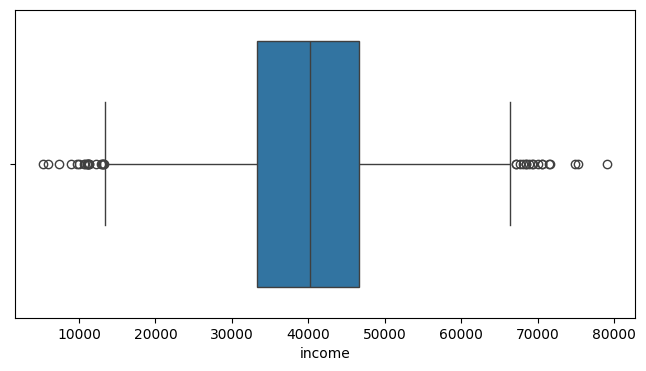

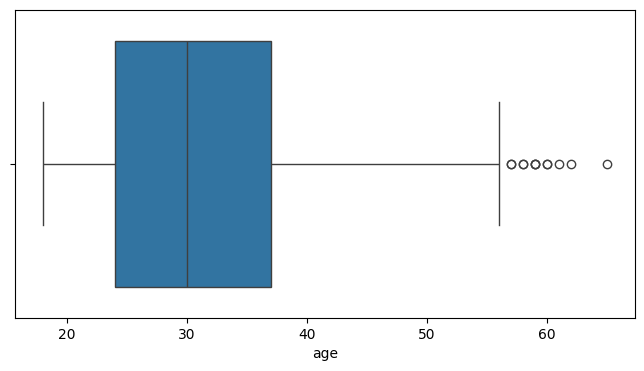

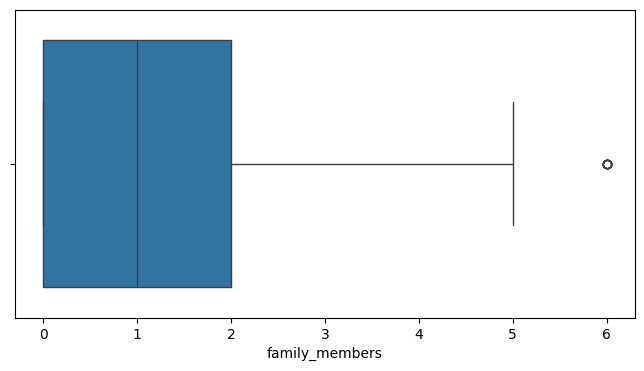

In [52]:
# Revisamos la distribución de los ingresos
plt.figure(figsize = (8, 4))
sns.boxplot(x = df["income"])


# Revisamos la distribución de la edad
plt.figure(figsize = (8, 4))
sns.boxplot(x = df["age"])

# Revisamos la distrubución de los miembros de familia
plt.figure(figsize = (8, 4))
sns.boxplot(x = df["family_members"])

Observando más detenidamente la variabilidad de los valores dentro de la característica de ingresos ("income") podemos ver mediante la gráfica que el valor medio ronda los 40.000 dolares anuales, y a pesar de que hay presentes valores extremos, la mayoría de estos datos se concentran de forma estable cerca a la media de los ingresos.

Analizando la variable de edad podemos ver que los clientes muestran una edad media de 30 años, no vemos mucha variabilidad respecto a esa edad pero si unos valores extremos respecto a edades que superan los 58 años.

Por último podemos observar que la característica de nuestro dataset que guarda la cantidad de miembros de las familias de los clientes se muestra como la de mayor estabilidad y menor variabilidad respecto a su valor medio, que es de un integrante. Registramos además un valor extremo de 6 miembros

## Análisis exploratorio de datos

Vamos a comprobar rápidamente si existen determinados grupos de clientes observando el gráfico de pares.

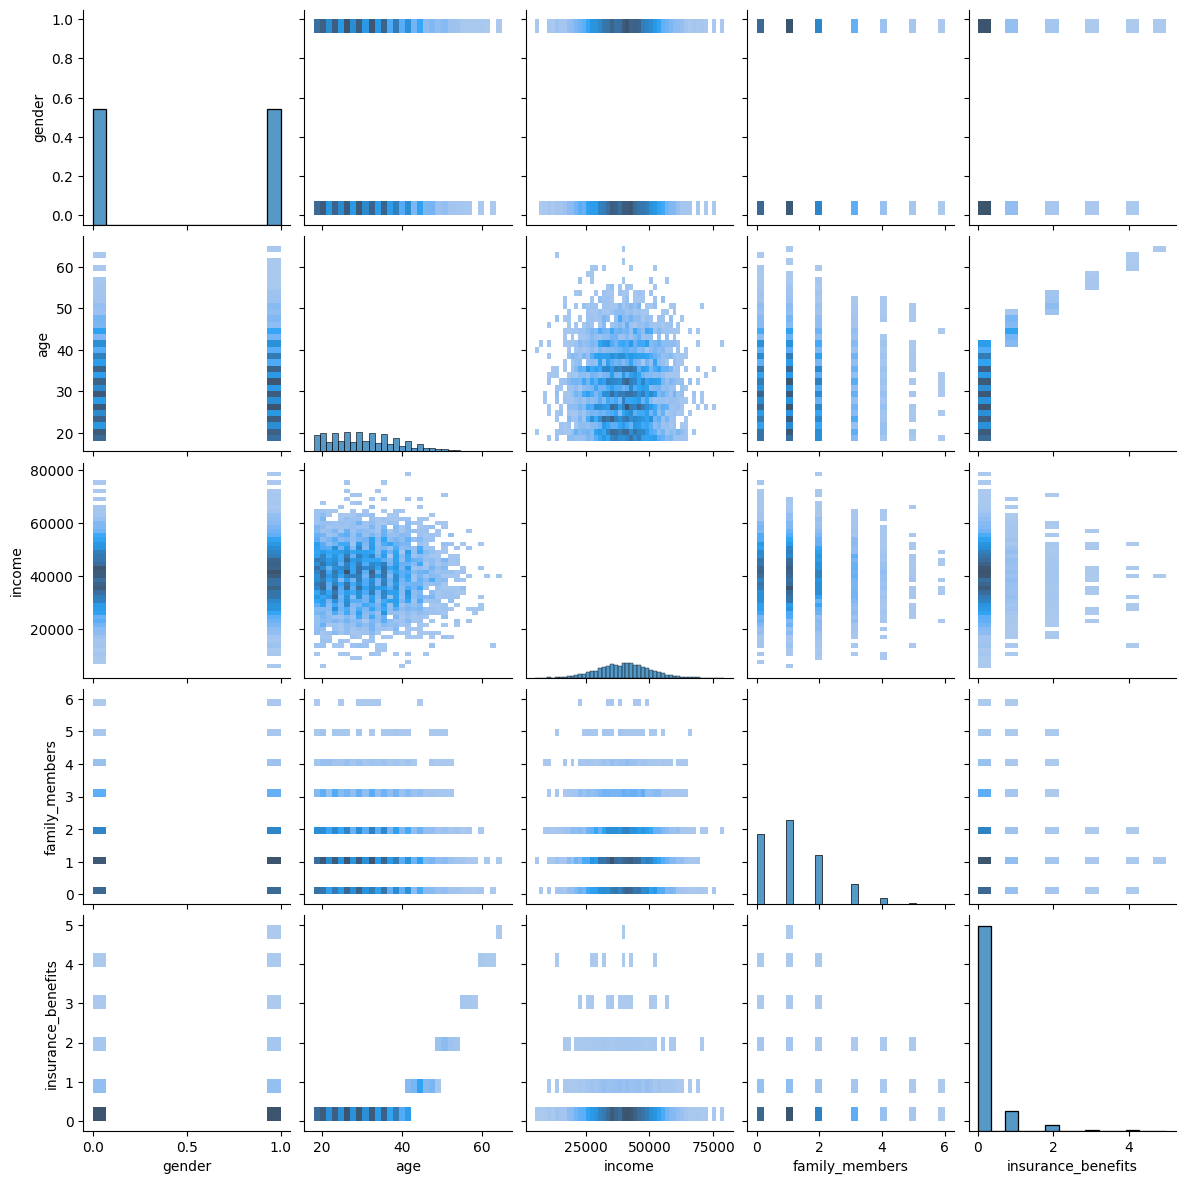

In [53]:
g = sns.pairplot(df, kind='hist')
g.fig.set_size_inches(12, 12)

De acuerdo, es un poco complicado detectar grupos obvios (clústeres) ya que es difícil combinar diversas variables simultáneamente (para analizar distribuciones multivariadas). Ahí es donde LA y ML pueden ser bastante útiles.

# Objetivo 1. Clientes similares

En el lenguaje de ML, es necesario desarrollar un procedimiento que devuelva los k vecinos más cercanos (objetos) para un objeto dado basándose en la distancia entre los objetos.

Para este trabajo, vamos a probar diferentes métricas de distancia.

# Función para identificar los k vecinos más cercanos de un cliente
# utilizando el algoritmo Nearest Neighbors.
#
# Parámetros:
# - df: DataFrame con los datos de los clientes.
# - n: índice del cliente de referencia.
# - k: número de vecinos a devolver.
# - metric: métrica de distancia ('euclidean' o 'manhattan').
#
# Procedimiento:
# 1. Crea un modelo NearestNeighbors.
# 2. Ajusta el modelo utilizando las variables seleccionadas.
# 3. Busca los k clientes más similares al cliente n.
# 4. Recupera las distancias y los índices de los vecinos.
# 5. Devuelve una tabla con los vecinos encontrados y su distancia
#    respecto al cliente analizado.

In [54]:
feature_names = ['gender', 'age', 'income', 'family_members']

In [55]:
def get_knn(df, n, k, metric):

    nbrs =  NearestNeighbors(
        n_neighbors=k,
        metric=metric
    )

    nbrs.fit(df[feature_names])

    nbrs_distances, nbrs_indices = nbrs.kneighbors([df.iloc[n][feature_names]], k, return_distance=True)

    df_res = pd.concat([
        df.iloc[nbrs_indices[0]],
        pd.DataFrame(nbrs_distances.T, index=nbrs_indices[0], columns=['distance'])
        ], axis=1)

    return df_res

Escalamos los datos.

En este bloque crearemos una copia del dataset y escalarenos las variables gender, age, income y family_members para que todas queden aproximadamente entre 0 y 1, evitando que variables grandes como income dominen los cálculos de distancia de KNN.

In [56]:
feature_names = ['gender', 'age', 'income', 'family_members']

transformer_mas = sklearn.preprocessing.MaxAbsScaler().fit(df[feature_names].to_numpy())

df_scaled = df.copy()
df_scaled.loc[:, feature_names] = transformer_mas.transform(df[feature_names].to_numpy())

/tmp/ipykernel_975/760832288.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.63076923 0.70769231 0.44615385 ... 0.30769231 0.33846154 0.43076923]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_scaled.loc[:, feature_names] = transformer_mas.transform(df[feature_names].to_numpy())
/tmp/ipykernel_975/760832288.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.16666667 0.16666667 0.         ... 0.33333333 0.5        0.16666667]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_scaled.loc[:, feature_names] = transformer_mas.transform(df[feature_names].to_numpy())


In [57]:
df_scaled.sample(5)

,gender,age,income,family_members,insurance_benefits
384,1,0.676923,0.567089,1.000000,1
1788,0,0.476923,0.600000,0.166667,0
1207,1,0.400000,0.334177,0.166667,0
209,0,0.338462,0.507595,0.166667,0
3515,1,0.292308,0.578481,0.166667,0


Para observar las diferencias del funcionamiento del algoritmo KNN en distintos casos usamos la función construída sobre el conjunto de datos original (sin escalado de datos) y sobre el dataset al cual le aplicamos el escalado.

Obtenemos las distancias de los vecinos más cercanos mediante la distancia euclidiana

In [58]:
print(get_knn(df, 100, 5, "euclidean"))

      gender  age   income  family_members  insurance_benefits  distance
100        0   19  37300.0               1                   0  0.000000
2624       1   19  37300.0               0                   0  1.414214
1831       0   20  37300.0               2                   0  1.414214
4278       1   19  37300.0               2                   0  1.414214
1086       0   22  37300.0               3                   0  3.605551


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


In [59]:
print(get_knn(df_scaled, 100, 5, "euclidean"))

      gender       age    income  family_members  insurance_benefits  distance
100        0  0.292308  0.472152        0.166667                   0  0.000000
4915       0  0.292308  0.477215        0.166667                   0  0.005063
243        0  0.292308  0.467089        0.166667                   0  0.005063
1323       0  0.292308  0.456962        0.166667                   0  0.015190
811        0  0.307692  0.470886        0.166667                   0  0.015437


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


Obtenemos las distancias de los vecinos más cercanos mediante la distancia euclidiana manhattan

In [60]:
print(get_knn(df, 100, 5, "manhattan"))

      gender  age   income  family_members  insurance_benefits  distance
100        0   19  37300.0               1                   0       0.0
2624       1   19  37300.0               0                   0       2.0
1831       0   20  37300.0               2                   0       2.0
4278       1   19  37300.0               2                   0       2.0
1086       0   22  37300.0               3                   0       5.0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


In [61]:
print(get_knn(df_scaled, 100, 5, "manhattan"))

      gender       age    income  family_members  insurance_benefits  distance
100        0  0.292308  0.472152        0.166667                   0  0.000000
4915       0  0.292308  0.477215        0.166667                   0  0.005063
243        0  0.292308  0.467089        0.166667                   0  0.005063
1323       0  0.292308  0.456962        0.166667                   0  0.015190
811        0  0.307692  0.470886        0.166667                   0  0.016650


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but NearestNeighbors was fitted with feature names
  warnings.warn(


**¿El hecho de que los datos no estén escalados afecta al algoritmo kNN? Si es así, ¿cómo se manifiesta?**

Señalamos que nuestra obervación objetivo en este caso es el cliente de la fila 100. Consideramos lógica una distancia eculiciana calculada en este caso de 0.0000

Podemos obervar que hay variables que matemáticamente se presentan como mayor en "importancia" para el algoritmo dada su superioridad en el valor puro que representan sin las etiquetas del dataset, como por ejemplo:

0, 19, 37300.0

El algoritmo podría colocar la variable de ingresos como predominante en importancia para los respectivos cálculos de las distancias para los vecinos más cercanos a nuestra obervación objetivo. Cuando ciertámente esto no es necesariamente cierto, funcional u obligatorio en nuestro conjunto de datos.

Podemos decir que el cáculo de la distancia estará dictaminado para el algoritmo en base fuertemente a una sola variable. Lo ideal es que sea influenciado por todas las variables que determinamos antes en medidas parecidaso comparables.

**¿Qué tan similares son los resultados al utilizar la métrica de distancia Manhattan (independientemente del escalado)?**

Ambas métricas identificaron exactamente los mismos vecinos más cercanos para el cliente analizado. Aunque los valores numéricos de las distancias son diferentes debido a la forma en que cada métrica las calcula, la similitud entre los clientes encontrados es prácticamente la misma.

# Objetivo 2. ¿Es probable que el cliente reciba una prestación del seguro?

En términos de machine learning podemos considerarlo como una tarea de clasificación binaria.

In [62]:
# сalculamos el objetivo

df["insurance_benefits_received"] = (df['insurance_benefits'] > 0).astype(int)
df = df.drop(["insurance_benefits"], axis = 1)

In [63]:
df_scaled.columns

Index(['gender', 'age', 'income', 'family_members', 'insurance_benefits'], dtype='object')

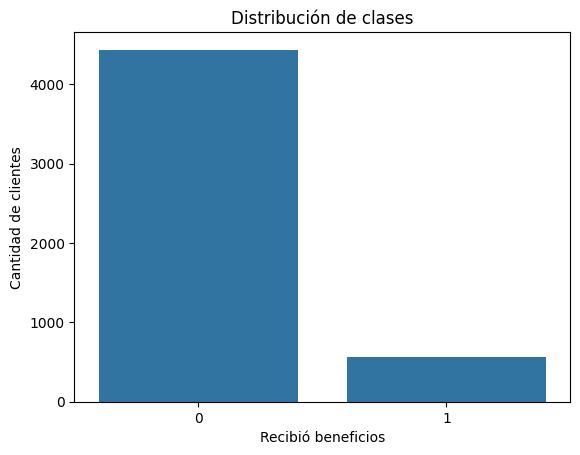

insurance_benefits_received
0    4436
1     564
Name: count, dtype: int64


In [64]:
# comprobamos el desequilibrio de clases con value_counts()

sns.countplot(x='insurance_benefits_received', data=df)

plt.title('Distribución de clases')
plt.xlabel('Recibió beneficios')
plt.ylabel('Cantidad de clientes')

plt.show()

print(df["insurance_benefits_received"].value_counts())

La variable objetivo presenta un fuerte desbalance de clases. Aproximadamente el 89% de los clientes no ha recibido beneficios de seguro, mientras que solo el 11% sí los ha recibido. Este desbalance debe tenerse en cuenta al evaluar los modelos de clasificación, ya que una alta exactitud (accuracy) podría resultar engañosa.

In [65]:
def eval_classifier(y_true, y_pred):

    f1_score = sklearn.metrics.f1_score(y_true, y_pred)
    print(f'F1: {f1_score:.2f}')

    cm = sklearn.metrics.confusion_matrix(y_true, y_pred, normalize='all')
    print('Matriz de confusión')
    print(cm)

In [66]:
# generar la salida de un modelo aleatorio

def rnd_model_predict(P, size, seed=42):

    rng = np.random.default_rng(seed=seed)
    return rng.binomial(n=1, p=P, size=size)

In [67]:
for P in [0, df['insurance_benefits_received'].sum() / len(df), 0.5, 1]:

    print(f'La probabilidad: {P:.2f}')
    y_pred_rnd = rnd_model_predict(P, len(df))

    eval_classifier(df['insurance_benefits_received'], y_pred_rnd)

    print()

La probabilidad: 0.00
F1: 0.00
Matriz de confusión
[[0.8872 0.    ]
 [0.1128 0.    ]]

La probabilidad: 0.11
F1: 0.12
Matriz de confusión
[[0.7914 0.0958]
 [0.0994 0.0134]]

La probabilidad: 0.50
F1: 0.20
Matriz de confusión
[[0.456  0.4312]
 [0.053  0.0598]]

La probabilidad: 1.00
F1: 0.20
Matriz de confusión
[[0.     0.8872]
 [0.     0.1128]]



Los resultados muestran que el modelo dummy presenta un rendimiento bajo en todos los escenarios evaluados. El mejor valor de F1 obtenido fue aproximadamente 0.20, por lo que cualquier clasificador KNN que supere este resultado podrá considerarse superior al modelo aleatorio de referencia. Esto nos proporciona una línea base contra la cual comparar el rendimiento de los modelos de clasificación desarrollados posteriormente.

In [68]:
# Separación de objetivo y características

target = df["insurance_benefits_received"]
features = df.drop(["insurance_benefits_received"], axis = 1)

In [69]:
df_scaled = df.copy()

df_scaled.loc[:, feature_names] = transformer_mas.transform(
    df[feature_names].to_numpy()
)

/tmp/ipykernel_975/576459178.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.63076923 0.70769231 0.44615385 ... 0.30769231 0.33846154 0.43076923]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_scaled.loc[:, feature_names] = transformer_mas.transform(
/tmp/ipykernel_975/576459178.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0.16666667 0.16666667 0.         ... 0.33333333 0.5        0.16666667]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_scaled.loc[:, feature_names] = transformer_mas.transform(


In [70]:
target_scaled = df_scaled["insurance_benefits_received"]
features_scaled = df_scaled.drop(["insurance_benefits_received"], axis = 1)

Separamos nuestro dataset en conjuntos de datos y validación

In [71]:
features_train, features_test, target_train, target_test = train_test_split(features, target, test_size = 0.3, random_state = 12345, shuffle = True)

In [72]:
for k in range(1, 11):

    model = KNeighborsClassifier(
        n_neighbors=k
    )

    model.fit(
        features_train,
        target_train
    )

    predictions = model.predict(
        features_test
    )

    print(f'k = {k}')

    eval_classifier(
        target_test,
        predictions
    )

    print()

k = 1
F1: 0.62
Matriz de confusión
[[0.87133333 0.02      ]
 [0.05133333 0.05733333]]

k = 2
F1: 0.41
Matriz de confusión
[[0.88733333 0.004     ]
 [0.08       0.02866667]]

k = 3
F1: 0.41
Matriz de confusión
[[0.88       0.01133333]
 [0.07733333 0.03133333]]

k = 4
F1: 0.28
Matriz de confusión
[[0.88866667 0.00266667]
 [0.09066667 0.018     ]]

k = 5
F1: 0.27
Matriz de confusión
[[0.88533333 0.006     ]
 [0.09066667 0.018     ]]

k = 6
F1: 0.11
Matriz de confusión
[[0.89       0.00133333]
 [0.102      0.00666667]]

k = 7
F1: 0.11
Matriz de confusión
[[0.88866667 0.00266667]
 [0.102      0.00666667]]

k = 8
F1: 0.07
Matriz de confusión
[[0.89133333 0.        ]
 [0.10466667 0.004     ]]

k = 9
F1: 0.08
Matriz de confusión
[[0.89133333 0.        ]
 [0.104      0.00466667]]

k = 10
F1: 0.00
Matriz de confusión
[[0.89133333 0.        ]
 [0.10866667 0.        ]]



El clasificador KNN superó ampliamente al modelo dummy en los valores más bajos de k. El mejor resultado se obtuvo con k=1, alcanzando un F1 de 0.62 frente al mejor F1 aproximado de 0.20 obtenido por el modelo aleatorio. También observamos que a medida que aumenta el número de vecinos, el rendimiento disminuye considerablemente. Esto puede explicarse por el fuerte desbalance de clases presente en el conjunto de datos, que favorece la predicción de la clase mayoritaria cuando la votación involucra un mayor número de vecinos.

Repetimos este proceso ahora para el dataset con los datos escalados

In [73]:
# Separaciónd del dataset en entrenamiento y prueba
features_scaled_train, features_scaled_test, target_scaled_train, target_scaled_test = train_test_split(features_scaled, target_scaled, test_size = 0.3, random_state = 12345, shuffle = True)


# Construcción del modelo KNN que mida el F1 dependiendo del número de k
for k in range(1, 11):

    model = KNeighborsClassifier(
        n_neighbors=k
    )

    model.fit(
        features_scaled_train,
        target_scaled_train
    )

    predictions = model.predict(
        features_scaled_test
    )

    print(f'k = {k}')

    eval_classifier(
        target_scaled_test,
        predictions
    )

    print()

k = 1
F1: 0.97
Matriz de confusión
[[0.88866667 0.00266667]
 [0.00466667 0.104     ]]

k = 2
F1: 0.93
Matriz de confusión
[[8.90666667e-01 6.66666667e-04]
 [1.40000000e-02 9.46666667e-02]]

k = 3
F1: 0.95
Matriz de confusión
[[0.88933333 0.002     ]
 [0.00866667 0.1       ]]

k = 4
F1: 0.91
Matriz de confusión
[[0.88933333 0.002     ]
 [0.01666667 0.092     ]]

k = 5
F1: 0.92
Matriz de confusión
[[0.88666667 0.00466667]
 [0.01133333 0.09733333]]

k = 6
F1: 0.90
Matriz de confusión
[[0.89       0.00133333]
 [0.018      0.09066667]]

k = 7
F1: 0.92
Matriz de confusión
[[0.88733333 0.004     ]
 [0.01266667 0.096     ]]

k = 8
F1: 0.90
Matriz de confusión
[[0.88866667 0.00266667]
 [0.01733333 0.09133333]]

k = 9
F1: 0.92
Matriz de confusión
[[0.88866667 0.00266667]
 [0.01466667 0.094     ]]

k = 10
F1: 0.88
Matriz de confusión
[[0.88866667 0.00266667]
 [0.02133333 0.08733333]]



Los resultados muestran que el clasificador KNN supera ampliamente al modelo dummy en todos los escenarios evaluados. El mejor modelo se obtuvo utilizando datos escalados y k=1, alcanzando un valor F1 de 0.97, frente al mejor resultado del modelo aleatorio, que fue aproximadamente 0.20.

También observamos que el escalado de los datos mejora significativamente el rendimiento del algoritmo. Esto se debe a que KNN calcula similitudes mediante distancias y, sin escalado, variables con magnitudes más elevadas, como los ingresos, dominan el cálculo.

Finalmente, se aprecia una disminución gradual del F1 a medida que aumenta el número de vecinos considerados. Este comportamiento probablemente está relacionado con el fuerte desbalance de clases presente en el conjunto de datos, que favorece la clase mayoritaria cuando aumenta el valor de k.

# Objetivo 3. Regresión (con regresión lineal)

Con `insurance_benefits` como objetivo, evalúa cuál sería la RECM de un modelo de regresión lineal.

Construye tu propia implementación de regresión lineal. Para ello, recuerda cómo está formulada la solución de la tarea de regresión lineal en términos de LA. Comprueba la RECM tanto para los datos originales como para los escalados. ¿Puedes ver alguna diferencia en la RECM con respecto a estos dos casos?

Denotemos
- $X$: matriz de características; cada fila es un caso, cada columna es una característica, la primera columna está formada por unidades
- $y$ — objetivo (un vector)
- $\hat{y}$ — objetivo estimado (un vector)
- $w$ — vector de pesos

La tarea de regresión lineal en el lenguaje de las matrices puede formularse así:

$$
y = Xw
$$

El objetivo de entrenamiento es entonces encontrar esa $w$ w que minimice la distancia L2 (ECM) entre $Xw$ y $y$:

$$
\min_w d_2(Xw, y) \quad \text{or} \quad \min_w \text{MSE}(Xw, y)
$$

Parece que hay una solución analítica para lo anteriormente expuesto:

$$
w = (X^T X)^{-1} X^T y
$$

La fórmula anterior puede servir para encontrar los pesos $w$ y estos últimos pueden utilizarse para calcular los valores predichos

$$
\hat{y} = X_{val}w
$$

Divide todos los datos correspondientes a las etapas de entrenamiento/prueba respetando la proporción 70:30. Utiliza la métrica RECM para evaluar el modelo.

In [74]:
df_original.columns

Index(['Gender', 'Age', 'Salary', 'Family members', 'Insurance benefits'], dtype='object')

In [75]:
target_original = df_original["Insurance benefits"]
features_original = df_original.drop(["Insurance benefits"], axis = 1)

In [76]:
features_original_train, features_original_test, target_original_train, target_original_test = train_test_split(features_original, target_original, test_size = 0.30, random_state = 12345, shuffle = True)

In [77]:
class MyLinearRegression:

    def __init__(self):

        self.weights = None

    def fit(self, X, y):

        # añadir las unidades
        X2 = np.append(np.ones([len(X), 1]), X, axis=1)

        self.weights = (
            np.linalg.inv(X2.T @ X2)
            @ X2.T
            @ y
        )

    def predict(self, X):

        # añadir las unidades
        X2 = np.append(np.ones([len(X), 1]), X, axis=1)

        y_pred = X2 @ self.weights

        return y_pred

In [78]:
def eval_regressor(y_true, y_pred):

    rmse = math.sqrt(
        sklearn.metrics.mean_squared_error(
            y_true,
            y_pred
        )
    )

    print(f'RMSE: {rmse:.2f}')

    r2_score = sklearn.metrics.r2_score(
        y_true,
        y_pred
    )

    print(f'R2: {r2_score:.2f}')


In [79]:
model = MyLinearRegression()

model.fit(
    features_original_train.to_numpy(),
    target_original_train.to_numpy()
)

predictions = model.predict(
    features_original_test.to_numpy()
)

eval_regressor(
    target_original_test,
    predictions
)

RMSE: 0.34
R2: 0.43


El modelo de regresión lineal obtuvo un RMSE de 0.34 y un R² de 0.44. Esto indica que el modelo es capaz de predecir la cantidad de beneficios de seguro con un error relativamente bajo y explicar aproximadamente el 44% de la variabilidad observada en la variable objetivo.

In [80]:
df.columns

Index(['gender', 'age', 'income', 'family_members',
       'insurance_benefits_received'],
      dtype='object')

In [81]:
X = df_original[['Age', 'Gender', 'Salary', 'Family members']].to_numpy()
y = df_original['Insurance benefits'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=12345
)

lr = MyLinearRegression()

lr.fit(X_train, y_train)

print(lr.weights)

y_test_pred = lr.predict(X_test)

eval_regressor(
    y_test,
    y_test_pred
)

[-9.43539012e-01  3.57495491e-02  1.64272726e-02 -2.60743659e-07
 -1.16902127e-02]
RMSE: 0.34
R2: 0.43


El modelo de regresión lineal desarrollado para predecir la cantidad de prestaciones de seguro obtuvo un RMSE de 0.34 y un R² de 0.43. Esto indica que las predicciones presentan un error promedio relativamente bajo y que el modelo es capaz de explicar aproximadamente el 43 % de la variabilidad observada en la variable objetivo.

Los resultados muestran que existe una relación entre las características de los clientes (Age, Gender, Salary y Family members) y la cantidad de prestaciones recibidas, aunque una parte importante de la variabilidad sigue dependiendo de factores no incluidos en el conjunto de datos.

# Objetivo 4 Ofuscar los datos

In [82]:
personal_info_column_list = ['gender', 'age', 'income', 'family_members']
df_pn = df[personal_info_column_list]

In [83]:
X = df_pn.to_numpy()

Generar una matriz aleatoria $P$.

In [84]:
rng = np.random.default_rng(seed=42)
P = rng.random(size=(X.shape[1], X.shape[1]))

Comprobar que la matriz P sea invertible

In [85]:
np.linalg.inv(P)

array([[ 0.41467992, -1.43783972,  0.62798546,  1.14001268],
       [-1.06101789,  0.44219337,  0.1329549 ,  1.18425933],
       [ 1.42362442,  1.60461607, -2.0553823 , -1.53699695],
       [-0.11128575, -0.65813802,  1.74995517, -0.11816316]])

La matriz aleatoria P es invertible, ya que fue posible calcular su matriz inversa utilizando np.linalg.inv(). Esto permite aplicar la transformación de enmascaramiento a los datos sin perder información, ya que los datos originales podrían recuperarse posteriormente mediante la matriz inversa.

In [89]:
X_masked = X @ P
X_masked[:5]

array([[ 6359.71527314, 22380.40467609, 18424.09074184, 46000.69669016],
       [ 4873.29406479, 17160.36702982, 14125.78076133, 35253.45577301],
       [ 2693.11742928,  9486.397744  ,  7808.83156024, 19484.86063067],
       [ 5345.60393712, 18803.22720286, 15479.14837264, 38663.06186284],
       [ 3347.17673462, 11782.82928336,  9699.99894205, 24211.27337753]])

Tras aplicar la transformación XPX=XP, los datos originales dejan de ser directamente interpretables. Los valores obtenidos son combinaciones lineales de las características originales y ya no permiten identificar de forma inmediata atributos como edad, ingresos, género o número de familiares. Por lo tanto, la información personal queda efectivamente enmascarada, dificultando la reconstrucción de los datos originales sin conocer la matriz de transformación utilizada.

In [92]:
P_inverse = np.linalg.inv(P)
X_recovered = X_masked @ P_inverse

In [95]:
X[:5]

array([[1.00e+00, 4.10e+01, 4.96e+04, 1.00e+00],
       [0.00e+00, 4.60e+01, 3.80e+04, 1.00e+00],
       [0.00e+00, 2.90e+01, 2.10e+04, 0.00e+00],
       [0.00e+00, 2.10e+01, 4.17e+04, 2.00e+00],
       [1.00e+00, 2.80e+01, 2.61e+04, 0.00e+00]])

In [96]:
X_recovered[:5]

array([[ 1.00000000e+00,  4.10000000e+01,  4.96000000e+04,
         1.00000000e+00],
       [-4.47363596e-12,  4.60000000e+01,  3.80000000e+04,
         1.00000000e+00],
       [-2.51586878e-12,  2.90000000e+01,  2.10000000e+04,
         9.52452315e-13],
       [-4.84498208e-12,  2.10000000e+01,  4.17000000e+04,
         2.00000000e+00],
       [ 1.00000000e+00,  2.80000000e+01,  2.61000000e+04,
        -1.01990740e-13]])

Tras multiplicar los datos por la matriz inversible PPP y posteriormente por su matriz inversa P−1P^{-1}P−1, se recuperaron prácticamente los mismos valores originales. Las pequeñas diferencias observadas son consecuencia de los errores de precisión inherentes a las operaciones numéricas en punto flotante y no representan una pérdida real de información. Esto demuestra que el procedimiento de enmascaramiento oculta los datos originales sin destruirlos y permite recuperarlos cuando se dispone de la matriz inversa correspondiente.

In [97]:
# Datos originales
X = df_pn.to_numpy()
y = df_original['Insurance benefits'].to_numpy()

# Datos enmascarados
X_masked = X @ P

# División de datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=12345
)

X_masked_train, X_masked_test, y_masked_train, y_masked_test = train_test_split(
    X_masked,
    y,
    test_size=0.3,
    random_state=12345
)

# Modelo con datos originales
lr_original = MyLinearRegression()

lr_original.fit(X_train, y_train)

y_pred_original = lr_original.predict(X_test)

print("Resultados con datos originales")
eval_regressor(y_test, y_pred_original)

print()

# Modelo con datos enmascarados
lr_masked = MyLinearRegression()

lr_masked.fit(X_masked_train, y_masked_train)

y_pred_masked = lr_masked.predict(X_masked_test)

print("Resultados con datos enmascarados")
eval_regressor(y_masked_test, y_pred_masked)

Resultados con datos originales
RMSE: 0.34
R2: 0.43

Resultados con datos enmascarados
RMSE: 0.34
R2: 0.43


Los resultados obtenidos con los datos originales y con los datos enmascarados son idénticos. Tanto el RMSE como el coeficiente de determinación R² conservan exactamente los mismos valores después de aplicar la transformación de enmascaramiento.

Esto demuestra que el procedimiento de enmascaramiento modifica la representación de los datos y dificulta la identificación directa de la información personal de los clientes, pero no altera las relaciones matemáticas contenidas en el conjunto de datos.

Por consiguiente, la regresión lineal mantiene la misma capacidad predictiva al trabajar con los datos transformados. Esto confirma que es posible proteger la privacidad de los clientes mediante el enmascaramiento sin afectar el rendimiento del modelo.